In [ ]:
!pip install pesq pystoi audiomentations #attenuate

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from tqdm import tqdm
from IPython.display import Audio, display
import os
from os import path
import soundfile as sf
import librosa
import torchaudio
import torchaudio.functional as F
import re
import json
from torch.optim import AdamW
from audiomentations import Compose, TimeStretch, PitchShift, Shift, PolarityInversion
import numpy as np
from google.colab import drive

In [ ]:
from torch.utils.data import Dataset
import gc
class BaseDenoisingDataset(Dataset):
  def collate_fn(self, batch):
    if self.mode == 'waveform':
      noisy, clean = map(list, zip(*batch))

      for i in range(len(noisy)):
        if noisy[i].shape[0] > 16_000*2:
          #dur = np.random.randint(16_000, 16_000 * 2)
          dur = 16_000 * 2
          beg = np.random.randint(0, noisy[i].shape[0] - dur)
          noisy[i] = noisy[i][beg:beg + dur]
          clean[i] = clean[i][beg:beg + dur]

      length = max(v.shape[0] for v in noisy)
      length += (self.addition - length%self.addition)%self.addition

      noisy_pad = torch.stack([
          torch.nn.functional.pad(val, (0, length - val.shape[0]))
          for val in noisy
      ])

      clean_pad = torch.stack([
          torch.nn.functional.pad(val, (0, length - val.shape[0]))
          for val in clean
      ])
      return noisy_pad, clean_pad

    if self.mode == 'spectrogram':
      time_axis = 2
      noisy, clean = map(list, zip(*batch))

      for i in range(len(noisy)):
        if noisy[i].shape[time_axis] > 16_000*2/256:
          #dur = np.random.randint(int(16_000/256), int(16_000 * 2/256))
          dur = int(16_000 * 2/256)
          beg = np.random.randint(0, noisy[i].shape[time_axis] - dur)
          mask = torch.zeros_like(noisy[i], dtype=torch.bool)
          mask[:,:,beg: beg + dur] = 1
          old_shape = noisy[i].shape
          noisy[i] = noisy[i][mask].reshape((old_shape[0], old_shape[1], -1))
          clean[i] = clean[i][mask].reshape((old_shape[0], old_shape[1], -1))

      length = max(v.shape[time_axis] for v in noisy)
      length += (self.addition - length%self.addition)%self.addition
      noisy_pad = torch.stack([
          torch.nn.functional.pad(val, (0, length - val.shape[time_axis]))
          for val in noisy
      ])

      clean_pad = torch.stack([
          torch.nn.functional.pad(val, (0, length - val.shape[time_axis]))
          for val in clean
      ])
      return noisy_pad, clean_pad

  def display(self, i, mode='clean', autoplay = True):
    idx = 1 if mode == 'clean' else 0
    display(Audio(self[i][idx], rate=self.sr, autoplay=autoplay, normalize=False))

  def display_augmentations(self, mode = 'clean'):
    idx = 1 if mode == 'clean' else 0
    if self.dual_aug == None:
      print('No augmentations')
    # display current?

    i = np.random.randint(len(self))

    self.no_augm_mode = True
    initial = self[i][idx].numpy()
    self.no_augm_mode = False

    print('Innitaial audio')
    display(Audio(initial, rate=self.sr, normalize=False))

    print('Time Stretch display')
    for rate in [0.5, 0.9, 1.1, 1.5]:
      print('Rate - ', rate)
      augmented = TimeStretch(min_rate=rate, max_rate=rate, p=1.0)(initial, self.sr)
      display(Audio(augmented, rate=self.sr, normalize=False))

    print('Pitch Shift display')

    for rate in [-3, -2, -1, 1, 2, 3]:
      print('semitones - ', rate)
      augmented = PitchShift(min_semitones=rate, max_semitones=rate, p=1)(initial, self.sr)
      display(Audio(augmented, rate=self.sr, normalize=False))

    print('Polarity Inversion display')

    for rate in ['']:
      print('Inverted sygnal is audibly unextinguishable')
      augmented = PolarityInversion(p=1)(initial, self.sr)
      display(Audio(augmented, rate=self.sr, normalize=False))


  def arr_to_sp(self, arr):
    raw_spectr = librosa.stft(arr, n_fft=512, hop_length=256, win_length=512)
    spectr = torch.stack((torch.tensor(raw_spectr.real),
                          torch.tensor(raw_spectr.imag)))
    return spectr


from datasets import load_dataset, Audio as datasets_Audio
class FolderDenoisingDataset(BaseDenoisingDataset):
  def __init__(self, data_path, train = True, sr = 16000, mode = 'waveform', dual_aug = None, mono_aug = None):
    self.sr = sr
    self.mode = mode
    self.dual_aug = dual_aug
    self.mono_aug = mono_aug
    self.no_augm_mode = False
    self.addition = 256
    self.train = train
    self.path = data_path
    self.path_clean = path.join(data_path, 'train' if train else 'test', 'clean')
    self.path_noisy = path.join(data_path, 'train' if train else 'test', 'noisy')
    self.files = sorted(
        f for f in os.listdir(self.path_clean)
        if f.lower().endswith(".wav")
    )
  def __getitem__(self, i):
    name = self.files[i]
    noisy = librosa.load(path.join(self.path_noisy, name), sr = self.sr)[0]
    clean = librosa.load(path.join(self.path_clean, name), sr = self.sr)[0]
    if self.dual_aug != None and not self.no_augm_mode:
      self.dual_aug.randomize_parameters(samples=noisy, sample_rate=self.sr)
      self.dual_aug.freeze_parameters()
      noisy = self.dual_aug(noisy, self.sr)
      clean = self.dual_aug(clean, self.sr)
      self.dual_aug.unfreeze_parameters()
    if self.mono_aug != None and not self.no_augm_mode:
      noisy = self.mono_aug(noisy, self.sr)
    if self.mode == 'waveform':
      return torch.tensor(noisy), torch.tensor(clean)
    elif self.mode == 'spectrogram':
      return self.arr_to_sp(noisy), self.arr_to_sp(clean)

  def __len__(self):
    return len(self.files)

  def get_all_durations(self):
    cnt = {}
    for i in tqdm(range(len(self))):
      info = sf.info(path.join(self.path_noisy, self.files[i]))
      dur = round(info.duration, 1)
      cnt[dur] = cnt.get(dur, 0) + 1
    return cnt

class HG_DenoisingDataset(BaseDenoisingDataset):
    def __init__(self, train=True, sr=16000, mode='waveform', dual_aug=None, mono_aug=None):
        self.sr = sr
        self.train = train
        self.mode = mode
        self.dual_aug = dual_aug
        self.mono_aug = mono_aug
        self.no_augm_mode = False
        self.addition = 256

        split_name = "train" if train else "test"
        self.dataset = load_dataset("JacobLinCool/VoiceBank-DEMAND-16k", split=split_name)

        self.dataset = self.dataset.cast_column("clean", datasets_Audio(sampling_rate=sr))
        self.dataset = self.dataset.cast_column("noisy", datasets_Audio(sampling_rate=sr))


    def __getitem__(self, i):
        item = self.dataset[i]
        noisy = item["noisy"]["array"]
        clean = item["clean"]["array"]

        if noisy.ndim > 1:
            noisy = noisy.mean(axis=1)
        if clean.ndim > 1:
            clean = clean.mean(axis=1)

        if self.dual_aug is not None and not self.no_augm_mode:
            self.dual_aug.randomize_parameters(samples=noisy, sample_rate=self.sr)
            self.dual_aug.freeze_parameters()
            noisy = self.dual_aug(noisy, self.sr)
            clean = self.dual_aug(clean, self.sr)
            self.dual_aug.unfreeze_parameters()

        if self.mono_aug is not None and not self.no_augm_mode:
            noisy = self.mono_aug(noisy, self.sr)

        if self.mode == 'waveform':
            return torch.tensor(noisy, dtype=torch.float32), torch.tensor(clean, dtype=torch.float32)
        elif self.mode == 'spectrogram':
            return self.arr_to_sp(noisy), self.arr_to_sp(clean)
        else:
            raise ValueError(f"Unknown mode: {self.mode}")

    def __len__(self):
        return len(self.dataset)

    def get_all_durations(self):
        cnt = {}
        for i in tqdm(range(len(self))):
            item = self.dataset[i]
            dur = round(len(item["noisy"]["array"]) / self.sr, 1)
            cnt[dur] = cnt.get(dur, 0) + 1
        return cnt

In [ ]:
drive.mount('/content/drive')
#!cp /content/drive/MyDrive/voicebank_plus_demand_16k /content/data -r

Mounted at /content/drive


In [ ]:
from audiomentations import Compose, TimeStretch, PitchShift, Shift, PolarityInversion
import numpy as np

standart_dual = Compose([
    PolarityInversion(p=0.5),
    TimeStretch(min_rate=0.9, max_rate=1.1, p=0.5),
    PitchShift(min_semitones=-2, max_semitones=2, p=0.6),
    #Shift(p=0.5),
])


In [ ]:
sampling_rate = 16000
my_path = "/content/data"
#training_dataset = BaseDenoisingDataset(my_path, sr=sampling_rate, dual_aug=standart_dual)
training_dataset = HG_DenoisingDataset(dual_aug=standart_dual)
training_dataset.display(9000, 'clean')

In [ ]:
'''
import seaborn as sns
plt.figure(figsize=(40, 5))
d = training_dataset.get_all_durations()
sns.barplot(d)
print(min(d.keys()), max(d.keys()))
s = sum([k * v for k, v in d.items()])
print(s/3600)
'''


'\nimport seaborn as sns\nplt.figure(figsize=(40, 5))\nd = training_dataset.get_all_durations()\nsns.barplot(d)\nprint(min(d.keys()), max(d.keys()))\ns = sum([k * v for k, v in d.items()])\nprint(s/3600)\n'

In [ ]:
from torch.utils.data import random_split
training_part, evaluation_part = random_split(training_dataset, [0.9, 0.1])

from torch.utils.data import DataLoader
# тестовые данные
evaluation_data = DataLoader(evaluation_part,
                           batch_size=24,
                           shuffle=False,
                           num_workers=2,
                           pin_memory=torch.cuda.is_available(),
                           prefetch_factor=6,
                           collate_fn=evaluation_part.dataset.collate_fn)
# обучающая выборка
train_data = DataLoader(training_part,
                           batch_size=8,
                           shuffle=True,
                           num_workers=2,
                           pin_memory=torch.cuda.is_available(),
                           prefetch_factor=16,
                           drop_last=True,
                           collate_fn=training_part.dataset.collate_fn)

# данные для оценки качества на обучающей выборке
train_representation, _ = random_split(training_part, [0.11, 0.89])
shortened_train_data = DataLoader(train_representation,
                                  batch_size=24,
                                  shuffle=False,
                                  num_workers=2,
                                  pin_memory=torch.cuda.is_available(),
                                  prefetch_factor=6,
                                  collate_fn=train_representation.dataset.dataset.collate_fn)

#my_path_test = "/content/data"
#my_path_test = "/content/drive/MyDrive/voicebank_demand_16k"

test_dataset = HG_DenoisingDataset(sr=sampling_rate, train=False)

test_data = DataLoader(test_dataset,
                        batch_size=1,
                        shuffle=False,
                        num_workers=2,
                        pin_memory=torch.cuda.is_available(),
                        prefetch_factor=6,
                        drop_last=True,
                        collate_fn=test_dataset.collate_fn)

In [ ]:
from pesq import pesq
from pystoi import stoi
from joblib import Parallel, delayed

def pesq_batch(sr, Y, X):
    X = X.detach().cpu().numpy() if X.is_cuda else X.detach().numpy()
    Y = Y.detach().cpu().numpy() if Y.is_cuda else Y.detach().numpy()

    pesq_score = Parallel(n_jobs=-1)(delayed(pesq)(sr, y, x, on_error=1)
                  for x, y in zip(Y, X))
    pesq_score = np.array(pesq_score)
    return pesq_score

def stoi_batch(Y, X, sr):
  X = X.detach().cpu().numpy() if X.is_cuda else X.detach().numpy()
  Y = Y.detach().cpu().numpy() if Y.is_cuda else Y.detach().numpy()
  stoi_score = Parallel(n_jobs=-1)(delayed(stoi)(y, x, sr)
                  for x, y in zip(Y, X))
  stoi_score = np.array(stoi_score)
  return stoi_score


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import random

class attennuate_loss_mod(nn.Module):
    def __init__(self, freq_weight=0.0011, time_weight=1.0, scales = [256, 512, 1024]):
        super().__init__()
        self.freq_weight = freq_weight
        self.time_weight = time_weight
        self.scales = scales
        for n_fft in scales:
            self.register_buffer(f'window_{n_fft}', torch.hann_window(n_fft))

    def stft_complex(self, x, res, window):
        return torch.stft(
            x,
            n_fft=res,
            hop_length=res//2,
            window=window,
            return_complex=True
        )

    def forward(self, input, target):
        time_loss = F.smooth_l1_loss(input, target, beta=0.5)
        freq_loss = 0.0

        for v in self.scales:
          window = getattr(self, f'window_{v}')
          input_stft = self.stft_complex(input, v, window)
          target_stft = self.stft_complex(target, v, window)

          input_stft = torch.abs(input_stft)
          target_stft = torch.abs(target_stft)

          freq_loss += torch.nn.functional.mse_loss(input_stft, target_stft)

        freq_loss /= len(self.scales)

        if torch.rand(1) > 0.998:
          print(time_loss.item()/freq_loss.item())

        return self.time_weight * time_loss + self.freq_weight * freq_loss

class attennuate_loss_phase(nn.Module):
    def __init__(self, freq_weight=0.0011, time_weight=1.0, scales = [256, 512, 1024]):
        super().__init__()
        self.freq_weight = freq_weight
        self.time_weight = time_weight
        self.scales = scales
        for n_fft in scales:
            self.register_buffer(f'window_{n_fft}', torch.hann_window(n_fft))

    def stft_complex(self, x, res, window):
        return torch.stft(
            x,
            n_fft=res,
            hop_length=res//2,
            window=window,
            return_complex=True
        )

    def forward(self, input, target):
        time_loss = F.smooth_l1_loss(input, target, beta=0.5)
        freq_loss = 0.0

        for v in self.scales:
          window = getattr(self, f'window_{v}')
          input_stft = self.stft_complex(input, v, window)
          target_stft = self.stft_complex(target, v, window)

          input_stft = torch.view_as_real(input_stft)
          target_stft = torch.view_as_real(target_stft)

          freq_loss += torch.nn.functional.mse_loss(input_stft, target_stft)

        freq_loss /= len(self.scales)

        if torch.rand(1) > 0.998:
          print(time_loss.item()/freq_loss.item())

        return self.time_weight * time_loss + self.freq_weight * freq_loss

class attennuate_loss_mel(nn.Module):
    def __init__(self, freq_weight=0.0011, n_mels = 40, time_weight=1.0, scales = [256, 512, 1024]):
        super().__init__()
        self.freq_weight = freq_weight
        self.time_weight = time_weight
        self.n_mels = n_mels
        self.scales = scales
        self.mel_transforms = nn.ModuleList([
            torchaudio.transforms.MelSpectrogram(n_fft=n_fft, n_mels=n_mels)
            for n_fft in scales
        ])


    def forward(self, input, target):
        time_loss = F.smooth_l1_loss(input, target, beta=0.5)
        freq_loss = 0.0

        for Mtransformation in self.mel_transforms:
          input_stft = Mtransformation(input)
          target_stft = Mtransformation(target)

          input_stft = torch.log(torch.clamp(input_stft, min=1e-5))
          target_stft = torch.log(torch.clamp(target_stft, min=1e-5))

          freq_loss += torch.nn.functional.l1_loss(input_stft, target_stft)

        freq_loss /= len(self.scales)

        if random.random() > 0.998:
          print(time_loss.item()/freq_loss.item())

        return self.time_weight * time_loss + self.freq_weight * freq_loss

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cuda


In [ ]:
from torch.utils.data import Subset, random_split
def evaluate(model, evaluating_data, dataset, device = torch.device('cpu'), verbose = True):
  model.to(device)
  model.eval()

  prev = dataset.no_augm_mode
  dataset.no_augm_mode = True
  #if  device.type == 'cuda':
  #  attenuate_pretrained = torch.compile(attenuate_pretrained, dynamic=True)

  pesq_sum = 0.0
  stoi_sum = 0.0
  for X, y in tqdm(evaluating_data, desc="  Evaluating"):
      X = X.to(device, non_blocking=True)

      if X.dim() == 2:
          X = X.unsqueeze(1)

      with torch.no_grad():
          #with torch.amp.autocast(device_type='cuda'):
          pred = model(X).squeeze()

          pred_cpu = pred.cpu()

      p_after = pesq_batch(sampling_rate, y, pred_cpu)
      pesq_sum += p_after.mean().item()

      s_after = stoi_batch(y, pred_cpu, sampling_rate)
      stoi_sum += s_after.mean().item()

  i = len(evaluating_data)
  if verbose:
    print(f'      PESQ: {pesq_sum/i:.4f}')
    print(f'      STOI: {stoi_sum/i:.4f}')

  dataset.no_augm_mode = prev
  return pesq_sum/i, stoi_sum/i

In [ ]:
from pathlib import Path
def train_a_model(model, loss, optimizer, training_data, train_for_evaluation, validation, dataset, params_path, period = 1, epochs=10):
  exp_path = Path(params_path)
  exp_path.mkdir(parents=True, exist_ok=True)
  device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
  loss_history = [[]]
  criterion = loss.to(device)
  #scaler = torch.amp.GradScaler('cuda')

  log_info = {
      'epochs_passed': 0,
      'metric_period': period,
      'loss_history': [],
      'pesq_train_history': [],
      'stoi_train_history': [],
      'pesq_valid_history': [],
      'stoi_valid_history': [],
  }
  log_path = os.path.join(params_path, 'log.json')
  if 'log.json' in os.listdir(params_path):
    with open(log_path, 'r') as f_read_log:
      log_info = json.load(f_read_log)
    if log_info['metric_period'] != period:
      raise RuntimeError('Incompatible evaluation periods')


  expmean_loss = 0
  for ep in range(log_info['epochs_passed'], epochs + log_info['epochs_passed']):
    model.train()
    pbar = tqdm(training_data, desc=f'Epoch {ep+1}')
    for i, (X, y) in enumerate(pbar):
      X = X.to(device, non_blocking=True)
      y = y.to(device, non_blocking=True)

      if X.dim() == 2:
          X = X.unsqueeze(1)

      #with torch.amp.autocast(device_type='cuda'):
      pred = model(X).squeeze()
      loss = criterion(pred, y)

      loss_history[-1].append(loss.item())
      expmean_loss = 0.9 * expmean_loss + 0.1 * loss.item()
      pbar.set_postfix(loss=f"{expmean_loss:.5f}")

      #scaler.scale(loss).backward()
      loss.backward()

      #scaler.unscale_(optimizer)
      torch.nn.utils.clip_grad_norm_(
          model.parameters(),
          max_norm=5.0
      )
      #scaler.step(optimizer)
      #scaler.update()
      optimizer.step()
      optimizer.zero_grad()

      #if i % 5 == 4:
      #  gc.collect()

    gc.collect()
    torch.cuda.empty_cache()

    log_info['epochs_passed'] += 1
    loss_ep_mean = np.array(loss_history[-1]).mean()
    log_info['loss_history'].append(loss_ep_mean)
    print('  Mean loss during epoch:', loss_ep_mean)
    loss_history.append([])

    if train_for_evaluation != None and (ep + 1) % period == 0:
      metrics_tmp = evaluate(model, train_for_evaluation, dataset, device)
      log_info['pesq_train_history'].append(metrics_tmp[0])
      log_info['stoi_train_history'].append(metrics_tmp[1])
    if validation != None and (ep + 1) % period == 0:
      metrics_tmp = evaluate(model, validation, dataset, device)
      log_info['pesq_valid_history'].append(metrics_tmp[0])
      log_info['stoi_valid_history'].append(metrics_tmp[1])
    print()

    gc.collect()
    torch.cuda.empty_cache()

    if (ep + 1) % period == 0:
      param_dist = params_path + f'/ep{ep+1}_params.pt'
      torch.save(model.state_dict(), param_dist)
      with open(log_path, "w") as outfile:
          json.dump(log_info, outfile)

  #return model, loss_history, metric_train_history, metric_test_history

In [ ]:
!pip install s5-pytorch

In [ ]:
from s5 import S5
import math
class MyAtennuate(nn.Module):
  class ssm_block(nn.Module):
    def __init__(self, ch, h, preconv = True, activation = True):
      super().__init__()
      self.preconv = (nn.Conv1d(ch, ch, 3, padding='same', groups = ch)
                      if preconv and ch > 1 else nn.Identity())
      self.activation = activation
      self.ch = ch
      self.h = h
      self.recurrence = S5(ch, h)
      self.LN = (nn.LayerNorm(ch)
                 if activation and ch > 1
                 else nn.Identity())
    def forward(self, x):
      x = self.preconv(x)
      x = x.transpose(1, 2)
      x = self.recurrence(x)
      x = self.LN(x)
      x = x.transpose(1, 2)
      if self.activation:
        x = nn.functional.silu(x)
      return x

  class encoder_block(nn.Module):
    def __init__(self, c_in, c_out, r, h=256, K = 1):
      super().__init__()
      self.c_in = c_in
      self.c_out = c_out
      self.K = K
      self.r = r
      self.h = h
      self.project = nn.Conv1d(c_in * r, c_out, K)
      self.ssm = MyAtennuate.ssm_block(c_in, h)

    def forward(self, x):
      x = self.ssm(x)
      y = x.clone()
      y = y.reshape(x.shape[0], x.shape[1], x.shape[2] // self.r, self.r)
      y = y.transpose(2, 3)
      y = y.reshape(x.shape[0], x.shape[1] * self.r, x.shape[2] // self.r)
      y = self.project(y)
      return x, y

  class decoder_block(nn.Module):
    def __init__(self, c_in, c_out, r, h=256, K = 1):
      super().__init__()
      self.c_in = c_in
      self.c_out = c_out
      self.K = K
      self.r = r
      self.h = h
      self.project = nn.Conv1d(c_in, c_out * r, K)
      self.ssm = MyAtennuate.ssm_block(c_out, h)

    def forward(self, x, y):
      x = self.project(x)
      B, _, T = x.shape
      x = x.reshape(B, self.c_out, self.r, T)
      x = x.transpose(3, 2)
      x = x.reshape(B, self.c_out, T * self.r)
      x = x + y
      x = self.ssm(x)
      return x

  def __init__(self, CH = [16, 32, 64, 96, 128, 256], R = [4, 4, 2, 2, 2, 2], h = 256):
    super().__init__()
    self.shr = math.prod(R)

    self.bottleneck1 = MyAtennuate.ssm_block(CH[-1], h, preconv = False)
    self.bottleneck2 = MyAtennuate.ssm_block(CH[-1], h, preconv = False)

    self.output_layer1 = MyAtennuate.ssm_block(1, h, preconv = False)
    self.output_layer2 = MyAtennuate.ssm_block(1, h, preconv = False, activation = False)

    enc = {}
    dec = {}

    for i in range(0, len(CH)):
      enc[f'encoder_{i}'] = MyAtennuate.encoder_block(1 if i == 0 else CH[i - 1], CH[i], R[i], h)
      dec[f'decoder_{i}'] = MyAtennuate.decoder_block(CH[i], 1 if i == 0 else CH[i - 1], R[i], h)

    self.encoder = nn.ModuleDict(enc)
    self.decoder = nn.ModuleDict(dec)

  def forward(self, x):
    #loudness = torch.max(torch.abs(x))
    #x /= loudness
    l = x.shape[-1]
    if l % self.shr:
      padd_l = self.shr - l % self.shr
      #print(padd_l)
      x = nn.functional.pad(x, (0, padd_l))
    enc_outputs = []

    Layers = sorted(self.encoder.items(), key = lambda x : int(x[0][8:]))
    for name, layer in Layers:
      y, x = layer(x)
      enc_outputs.append(y)

    x = self.bottleneck1(x)
    x = self.bottleneck2(x)

    Layers = sorted(self.decoder.items(), key = lambda x : int(x[0][8:]))
    for name, layer in Layers[::-1]:
      i = int(name[8:])
      x = layer(x, enc_outputs[i])

    x = self.output_layer1(x)
    x = self.output_layer2(x)
    #x *= loudness
    return x[...,:l]

In [ ]:
model = MyAtennuate(CH = [16, 32, 64, 96, 128], R = [4, 4, 2, 2, 2], h = 128)
model.to(device)
from torchsummary import summary
#summary(model, (1, 256*4))
total = sum(p.numel() for p in model.parameters())
print(total)

353784


In [ ]:
#model.load_state_dict(torch.load('/content/drive/MyDrive/my_att_l1_noaug/ep8_params.pt', device))

In [ ]:
train_a_model(model,
              ERB_loss(),
              AdamW(model.parameters(), lr=5e-3, weight_decay=0.001),
              train_data,
              shortened_train_data,
              evaluation_data,
              training_dataset,
              '/content/drive/MyDrive/my_att_erb_noaug',
              epochs = 1,
              period = 1)

Epoch 1:  38%|███▊      | 499/1301 [07:23<11:52,  1.13it/s, loss=0.00284]

0.000490380470985501


Epoch 1:  95%|█████████▌| 1239/1301 [18:02<00:53,  1.17it/s, loss=0.00250]

0.00029822694328812807


Epoch 1:  99%|█████████▉| 1287/1301 [18:43<00:11,  1.17it/s, loss=0.00254]

...

  Mean loss during epoch: 0.0038708699569156213


  Evaluating: 100%|██████████| 48/48 [02:17<00:00,  2.86s/it]


      PESQ: 1.8119
      STOI: 0.8739


  Evaluating: 100%|██████████| 49/49 [02:17<00:00,  2.81s/it]


      PESQ: 1.7752
      STOI: 0.8681



In [ ]:
gc.collect()
torch.cuda.empty_cache()
del model

In [ ]:
def visualise_reports(way_name, separate = True):
  fig, ax = plt.subplots(3, 1, figsize = (10, 10))
  ax[0].set_title('loss_history')
  ax[1].set_title('PESQ_history')
  ax[2].set_title('STOI_history')
  for log_path, exp_name in way_name.items():
    with open(log_path, 'r') as f:
      data = json.load(f)
    ax[0].plot(np.arange(1, data['epochs_passed'] + 1), data['loss_history'], label = exp_name)
    ep_range = np.arange(data['metric_period'], data['epochs_passed'] + 1, data['metric_period'])
    ax[1].plot(ep_range, data['pesq_train_history'], '-', label = exp_name)
    ax[1].plot(ep_range, data['pesq_valid_history'], '--', label = exp_name)
    ax[2].plot(ep_range, data['stoi_train_history'], '-', label = exp_name)
    ax[2].plot(ep_range, data['stoi_valid_history'], '--', label = exp_name)
  #ax[1].set_ylim(1, 3.5)
  #ax[2].set_ylim(0, 1)
  ax[0].legend()
  ax[1].legend()
  ax[2].legend()

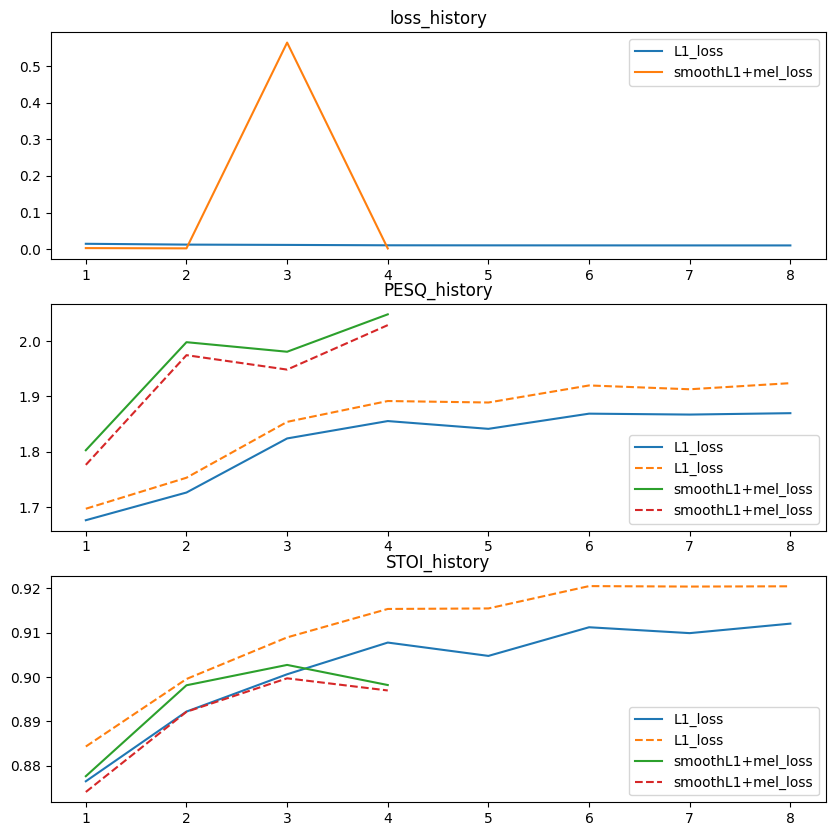

In [ ]:
visualise_reports({'/content/drive/MyDrive/my_att_l1_noaug/log.json':'L1_loss',
                   '/content/drive/MyDrive/my_att_lsp3_noaug/log.json':'smoothL1+mel_loss'})